# Llamadas 911 Primer Semestre del 2022

---
### Introducción

El presente proyecto analiza las llamadas de emergencia al 911 en la Ciudad de México durante el primer semestre del año 2022. El objetivo es identificar las alcaldías o colonias que requieren con mayor frecuencia apoyo, las categorías de incidentes más reportadas y cómo estos patrones cambian a lo largo del tiempo.

### Importancia y relevancia del problema
Identificar las zonas con mayor demanda de atención y los tipos de incidentes más frecuentes es información que puede contribuir a una mejor distribución de recursos y a la planeación de estrategias de prevención.
### Objetivos específicos
*   Identificar las alcaldías y colonias con mayor número de llamadas de emergencia.
*   Determinar las categorías de incidentes más frecuentes.

### Hipótesis
Se plantea que existen alcaldías con una concentración mayor de llamadas, que ciertos tipos de incidentes predominan sobre otros y que la frecuencia de los reportes presenta variaciones según el periodo analizado.



---




# 1.   Manejo de datos




Se importa el conjunto de datos desde una fuente externa (archivo CSV) de la página del Portal de Datos Abiertos del Gobierno de la Ciudad de México que se encuentra en https://datos.cdmx.gob.mx/dataset/llamadas-numero-de-atencion-a-emergencias-911/resource/c752b1e2-bfec-4c7b-b46f-ddb433bfb6a2

In [ ]:
from google.colab import drive
import pandas as pd

# Monta tu Google Drive (te pedirá un código de autenticación)
drive.mount('/content/drive')

# Coloca la ruta exacta de tu archivo en Drive
ruta = '/content/drive/MyDrive/TC_PRO/Proyecto Final M3/llamadas_911_2022_s1.csv'

# Lee el archivo .csv
df = pd.read_csv(ruta)

Mounted at /content/drive


Con **df.head()** se muestran las primeras filas del Data Frame:

In [ ]:
df.head()

,folio,categoria_incidente_c4,incidente_c4,anio_creacion,mes_creacion,fecha_creacion,hora_creacion,anio_cierre,mes_cierre,fecha_cierre,hora_cierre,codigo_cierre,clas_con_f_alarma,alcaldia_cierre,colonia_cierre,manzana,latitud,longitud
0,C5/20220110/02402,Medicos,Dolor,2022,Enero,2022-01-10,17:01:37,2022,Enero,2022-01-10,20:04:48,Otros,URGENCIAS MEDICAS,IZTAPALAPA,LOS ANGELES,9.01E+14,19.342547,-99.064753
1,C5/20220129/01383,Derrame o fuga,Olor a gas combustible quimicos,2022,Enero,2022-01-29,10:39:06,2022,Enero,2022-01-29,13:46:10,Otros,EMERGENCIA,IZTACALCO,REFORMA IZTACCIHUATL NORTE,9.01E+14,19.383764,-99.125159
2,C5/20220129/02670,Cadaver,Muerte causa ignorada,2022,Enero,2022-01-29,16:28:36,2022,Enero,2022-01-29,21:16:09,A,EMERGENCIA,IZTAPALAPA,EL SANTUARIO,9.01E+14,19.355138,-99.094547
3,C5/20220129/02432,Cadaver,Muerte por enfermedad previamente diagnosticada,2022,Enero,2022-01-29,15:28:21,2022,Enero,2022-01-29,19:26:09,A,EMERGENCIA,IZTAPALAPA,SAN JOSE ACULCO,9.01E+14,19.378243,-99.099509
4,C5/20220129/02220,Cadaver,Muerte por enfermedad previamente diagnosticada,2022,Enero,2022-01-29,14:33:10,2022,Enero,2022-01-29,20:36:10,A,EMERGENCIA,CUAUHTEMOC,SAN RAFAEL I,9.02E+14,19.433425,-99.159037


Con **df.tail()** se muestran las últimas filas del Data Frame:

In [ ]:
df.tail()

,folio,categoria_incidente_c4,incidente_c4,anio_creacion,mes_creacion,fecha_creacion,hora_creacion,anio_cierre,mes_cierre,fecha_cierre,hora_cierre,codigo_cierre,clas_con_f_alarma,alcaldia_cierre,colonia_cierre,manzana,latitud,longitud
390056,C5/200926/05975,Denuncia,Persona desaparecida,2020,Septiembre,2020-09-26,16:31:11,2022,Abril,2022-04-17,07:48:45,Otros,SERVICIO,TLAHUAC,SAN PEDRO TLAHUAC (PBLO),9.011E+14,19.270966,-99.003304
390057,C5/200414/00990,Denuncia,Persona desaparecida,2020,Abril,2020-04-14,05:47:13,2022,Abril,2022-04-18,14:51:55,Otros,SERVICIO,BENITO JUAREZ,SAN JOSE INSURGENTES,9.014E+14,19.363858,-99.186088
390058,C5/200718/02912,Servicios,Vehiculo obstruyendo,2020,Julio,2020-07-18,09:16:28,2022,Abril,2022-04-19,23:00:19,Otros,SERVICIO,COYOACAN,LAS CAMPANAS,090030001143A025,19.307374,-99.120861
390059,C5/200724/02605,Denuncia,Persona desaparecida,2020,Julio,2020-07-24,10:59:13,2022,Abril,2022-04-26,19:58:11,Otros,SERVICIO,MIGUEL HIDALGO,SAN DIEGO OCOYOACAC,090160001004A020,19.461359,-99.191119
390060,C5/201004/07304,Denuncia,Persona desaparecida,2020,Octubre,2020-10-04,21:06:00,2022,Abril,2022-04-29,12:11:00,Otros,SERVICIO,COYOACAN,LOS OLIVOS (U HAB),9.003E+14,19.313016,-99.134008


Se desea saber qué tipo de dataset se tiene para poder analizarla. Lo cual nos arroja 390061 filas y 18 columnas con la función **df.shape()** por lo que se trata de una matriz bidimensional.

In [ ]:
total_filas, total_columnas = df.shape
print(f"Filas: {total_filas}, Columnas: {total_columnas}")

Filas: 390061, Columnas: 18


Con el atributp **df.dtypes** sabemos el tipo de dato de cada columna. Y con **df.size** el número total de elementos o celdas de nuestro Data Frame, es decir 390061 filas por 18 columnas = 7021098 como total de elementos, lo cual es indica que estamos trabajando con una base de datos amplia y con columnas que la mayoría son de tipo **object**.

In [ ]:
df.dtypes

,0
folio,object
categoria_incidente_c4,object
incidente_c4,object
anio_creacion,int64
mes_creacion,object
fecha_creacion,object
hora_creacion,object
anio_cierre,int64
mes_cierre,object
fecha_cierre,object


In [ ]:
df.size

7021098

De igual manera, es posible verificar que nuestro Data Frame no esté vacío con **df. empty** que entrega un resultado de tipo booleano, es decir Verdadero o Falso. Y con **df.isna().any()** podemos ver qué folios tienen filas vacías.

In [ ]:
df.empty

False

In [ ]:
df.isna().any()

,0
folio,False
categoria_incidente_c4,False
incidente_c4,True
anio_creacion,False
mes_creacion,False
fecha_creacion,False
hora_creacion,False
anio_cierre,False
mes_cierre,False
fecha_cierre,False


Además de saber cuántas categorías por incidente,colonias, alcaldías e incidentes diferentes hay en nuestro DF.

In [ ]:
total_categorias = df['categoria_incidente_c4'].nunique()
print(f"Hay {total_categorias} categorías generales únicas.")

total_incidentes = df['incidente_c4'].nunique()
print(f"Hay {total_incidentes} incidentes específicos únicos.")

total_colonias = df['colonia_cierre'].nunique()
print(f"Hay {total_colonias} colonias únicas.")

total_alcaldias = df['alcaldia_cierre'].nunique()
print(f"Hay {total_alcaldias} alcaldías únicas.")

Hay 23 categorías generales únicas.
Hay 200 incidentes específicos únicos.
Hay 1725 colonias únicas.
Hay 17 alcaldías únicas.


# 2. Trato de datos

Antes de comenzar con el trato de datos, hacemos una copia del DataFrame con  **df.copy(deep=True)**

In [ ]:
df_copia = df.copy(deep=True)

Con **df.info()** podemos ver toda la información que obtuvimos anteriormente pero más completa y ordenada. Además de que se puede ver cuántas filas vacías hay en cada columna e incluso ver la memoria que ocupa.

In [ ]:
df_copia .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390061 entries, 0 to 390060
Data columns (total 18 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   folio                   390061 non-null  object 
 1   categoria_incidente_c4  390061 non-null  object 
 2   incidente_c4            390039 non-null  object 
 3   anio_creacion           390061 non-null  int64  
 4   mes_creacion            390061 non-null  object 
 5   fecha_creacion          390061 non-null  object 
 6   hora_creacion           390061 non-null  object 
 7   anio_cierre             390061 non-null  int64  
 8   mes_cierre              390061 non-null  object 
 9   fecha_cierre            390061 non-null  object 
 10  hora_cierre             390061 non-null  object 
 11  codigo_cierre           390061 non-null  object 
 12  clas_con_f_alarma       390061 non-null  object 
 13  alcaldia_cierre         390061 non-null  object 
 14  colonia_cierre      

Como existen filas vacías en incidente_c4 y manzana podemos usar **df_copia.dropna()**, sin embargo para no perder las filas completas rellenamos a "SIN DATO".


In [ ]:
df_copia["incidente_c4"] = df_copia["incidente_c4"].fillna("SIN DATO")

df_copia["manzana"] = df_copia["manzana"].fillna("SIN DATO")

Con **df.duplicated()** verificamos si existen filas duplicadas. Por lo que no existen ya que está vacía.

In [ ]:
duplicados = df[df_copia.duplicated()]
print(duplicados)

Empty DataFrame
Columns: [folio, categoria_incidente_c4, incidente_c4, anio_creacion, mes_creacion, fecha_creacion, hora_creacion, anio_cierre, mes_cierre, fecha_cierre, hora_cierre, codigo_cierre, clas_con_f_alarma, alcaldia_cierre, colonia_cierre, manzana, latitud, longitud]
Index: []


# 3. Análisis exploratorio y manipulación de datos

Renombramos algunas columnas para que sea más fácil la manipulación de la DF con **df.rename()** .

In [ ]:
df_copia.rename(columns={'alcaldia_cierre': 'alcaldia', 'colonia_cierre': 'colonia', 'categoria_incidente_c4': 'categoria', 'incidente_c4': 'incidente'}, inplace=True)

Realizamos una agrupación con **df.groupby()** que consiste en Split-Apply-Combine (Dividir-Aplicar-Combinar). Por lo que se observa los incidentes con mayor número de llamadas, los cuales están de "Persona" en la alcaldia Iztapalapa y Cuauhtemoc, seguido por Gustavo A. Madero, y los incidentes menos ocurridos son inhalacion de gas químicos, bancos, intoxicación, electrocutado o quemado.

In [ ]:
df_copia.groupby(["alcaldia", "incidente"], sort=False).size().sort_values(ascending=False)

alcaldia               incidente                     
IZTAPALAPA             Persona                           8105
CUAUHTEMOC             Persona                           5584
IZTAPALAPA             Escandalo                         5525
GUSTAVO A. MADERO      Persona                           5343
                       Escandalo                         5037
                                                         ... 
IZTAPALAPA             Deslave                              1
CUAJIMALPA DE MORELOS  Animales                             1
BENITO JUAREZ          Venta de pirotecnia                  1
COYOACAN               Inhalacion de gas quimicos           1
VENUSTIANO CARRANZA    Se arrojo a las vias del metro       1
Length: 2440, dtype: int64

Ahora bien, ya se sabe los incidentes mayormente y menormente ocurridos. Por lo que para saber las alcaldías con mayor número de incidentes se realiza lo siguiente. Por lo que se observa que Iztapalapa es el que tiene mayor número de incidentes y Cuajimalpa el que menos.

In [ ]:
df_copia.groupby("alcaldia", sort=False).size().sort_values(ascending=False)

,0
alcaldia,
IZTAPALAPA,65168
GUSTAVO A. MADERO,48811
CUAUHTEMOC,43412
COYOACAN,28246
ALVARO OBREGON,27880
VENUSTIANO CARRANZA,25140
TLALPAN,24831
BENITO JUAREZ,23849
MIGUEL HIDALGO,20534


## 4. Aplicación de  funciones y expresiones

Utilizamos la función lambda para limpiar el texto.

In [ ]:
def limpiar_texto(texto):
    try:
        #  quitar espacios y convertir a mayúsculas
        return str(texto).strip().upper()
    except Exception as e:
        return "SIN DATO"

df_copia['alcaldia'] = df_copia['alcaldia'].apply(lambda x: limpiar_texto(x))
df_copia['incidente'] = df_copia['incidente'].apply(lambda x: limpiar_texto(x))

Creamos un diccionario de falsos reportes para que con el método **map()** reemplace los valores.

In [ ]:
print(df_copia['clas_con_f_alarma'].value_counts(dropna=False))
diccionario_estatus = {

    'FALSA ALARMA': 'Falsa Alarma'
}
df_copia['tipo_reporte'] = df_copia['clas_con_f_alarma'].map(diccionario_estatus)

clas_con_f_alarma
SERVICIO             113333
DELITO                92827
FALTA CÍVICA          85220
URGENCIAS MEDICAS     64361
EMERGENCIA            34317
FALSA ALARMA              3
Name: count, dtype: int64


Donde se demuestra que prácticamente todas las llamadas atendidas corresponden a servicios reales ya que slo 3 llamadas han sido falsas.

El método **reduce()** permite aplicar una operación en cadena y reducirla a un solo resultado. En lo siguiente, obtenemos el conteo total de llamadas de 3 alcaldías individuales.

In [ ]:
from functools import reduce

llamadas_iztapalapa = len(df_copia[df_copia['alcaldia'] == 'IZTAPALAPA'])
llamadas_cuauhtemoc = len(df_copia[df_copia['alcaldia'] == 'CUAUHTEMOC'])
llamadas_gam = len(df_copia[df_copia['alcaldia'] == 'GUSTAVO A. MADERO'])

lista_totales = [llamadas_iztapalapa, llamadas_cuauhtemoc, llamadas_gam]

gran_total_zonas_criticas = reduce(lambda acumulado, elemento: acumulado + elemento, lista_totales)

print(f"El total combinado de llamadas en las 3 zonas críticas es: {gran_total_zonas_criticas}")

El total combinado de llamadas en las 3 zonas críticas es: 157391


El procesamiento de 390,061 llamadas al 911 en el primer semestre de 2022 revela una alta concentración en tres alcaldías (Iztapalapa, Gustavo A. Madero y Cuauhtémoc), las cuales acumulan un total combinado de 157,391 reportes (liderando Iztapalapa con 65,168). Las categorías con mayor frecuencia de incidentes tipo 'Persona' en Iztapalapa (8,105) y Cuauhtémoc (5,584), seguidas de 'Escándalo' en Iztapalapa (5,525), mientras que eventos como accidentes químicos representan casos marginales de un solo registro. Basado en estos insights, y tras corregir errores de consistencia en el registro, se recomienda a las autoridades de seguridad pública centralizar el despliegue de patrullajes dinámicos en estas alcaldías, canalizar las llamadas de índole social/vecinal.

# Modulo 3 Proyecto final

1. Estimados de
locación y
variabilidad

Convertimos la columna de fecha a formato **datetime** para realizar un conteo diario de llamadas con **groupby**, y con ello realizar los estimados de locación.

In [ ]:
df_copia['fecha_creacion'] = pd.to_datetime(df_copia['fecha_creacion'])
llamadas_por_dia = df_copia.groupby(df_copia['fecha_creacion'].dt.date).size()
print(f"Promedio (media): {llamadas_por_dia.mean(): .2f}")
print(f"Mediana: {llamadas_por_dia.median(): .2f}")
print(f"Moda: {int(llamadas_por_dia.mode().iloc[0])}")
print( "============================================\n")

print(f"Varianza: {llamadas_por_dia.var():.2f}")
print(f"Desviación Estándar: {llamadas_por_dia.std():.2f}")
print(f"Rango: {llamadas_por_dia.max()-llamadas_por_dia.min():.2f}")

print( "============================================\n")
print(f"Cuartiles: {llamadas_por_dia.quantile([0.25, 0.5, 0.75])}")
print(f"Percentiles 90%: {llamadas_por_dia.quantile(0.9)}")

#posibles outliers
print( "============================================\n")
print(f"5 días con mayor número de llamadas: {llamadas_por_dia.nlargest(5)}")
print(f"5 días con menor número de llamadas: {llamadas_por_dia.nsmallest(5)}")

print( "============================================\n")
print("Alcaldias con mayor número de llamadas \n")
top_colonias = df_copia['alcaldia'].value_counts().nlargest(5)
print(top_colonias)

print( "============================================\n")
print("Colonias con mayor número de llamadas \n")
top_colonias = df_copia['colonia'].value_counts().nlargest(5)
print(top_colonias)




Promedio (media):  2453.21
Mediana:  2720.00
Moda: 1

Varianza: 2447373.99
Desviación Estándar: 1564.41
Rango: 6209.00

Cuartiles: 0.25    2114.5
0.50    2720.0
0.75    3403.0
dtype: float64
Percentiles 90%: 4237.200000000002

5 días con mayor número de llamadas: fecha_creacion
2022-04-16    6210
2022-01-01    6025
2022-04-02    5265
2022-04-03    5188
2022-04-24    5019
dtype: int64
5 días con menor número de llamadas: fecha_creacion
2020-03-07    1
2020-03-18    1
2020-04-14    1
2020-04-16    1
2020-04-28    1
dtype: int64

Alcaldias con mayor número de llamadas 

alcaldia
IZTAPALAPA           65168
GUSTAVO A. MADERO    48811
CUAUHTEMOC           43412
COYOACAN             28246
ALVARO OBREGON       27880
Name: count, dtype: int64

Colonias con mayor número de llamadas 

colonia
JUAREZ            2216
CENTRO IV         1984
CENTRO VIII       1611
CUAUHTEMOC        1541
ROMA NORTE III    1455
Name: count, dtype: int64


De acuerdo con la información anterior, es posible observar que en días festivos es cuando se recibe la mayor parte de reportes como en año nuevo, o cerca de las vacaciones de Semana Santa (abril). Además de que la mayoría de las llamadas se realizan en Iztapalapa. Por lo que, 2720 llamadas al día es el valor que mayormente representa un día en CDMX, de los cuales el 50% de los días normales se ubica entre 2115 y 3403 llamadas diarias. Mientras que solo el 10% de los días superan las 4237 llamadas diarias.

# 2. Visualización dedatos: distribuciones


categoria       Abandono  Accidente  Administrativas  Agresion  Amenaza  \
alcaldia                                                                  
ALVARO OBREGON       327          2             2809      3931      115   
AZCAPOTZALCO         206          0             1897      2525       74   
BENITO JUAREZ        250          0             1446      3207      102   
COYOACAN             313          0             2992      4241      146   
CUAJIMALPA             0          0                0         1        1   

categoria       Cadaver  Contra la salud  Danos  \
alcaldia                                          
ALVARO OBREGON      249              130    359   
AZCAPOTZALCO        167               98    217   
BENITO JUAREZ       127               53    333   
COYOACAN            212              124    458   
CUAJIMALPA            1                0      0   

categoria       Danos por fenomeno natural o tercero  Denuncia  ...  Incendio  \
alcaldia                          

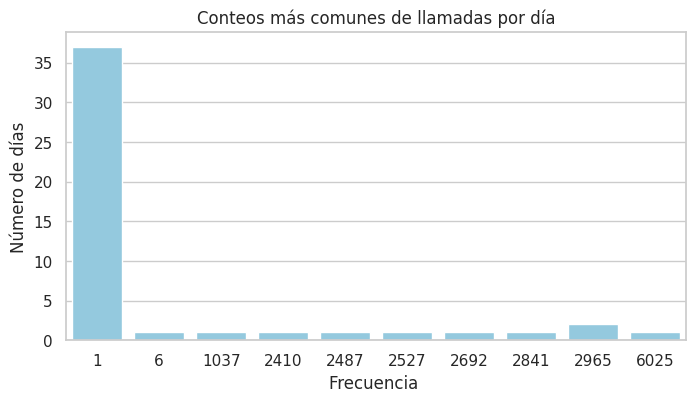

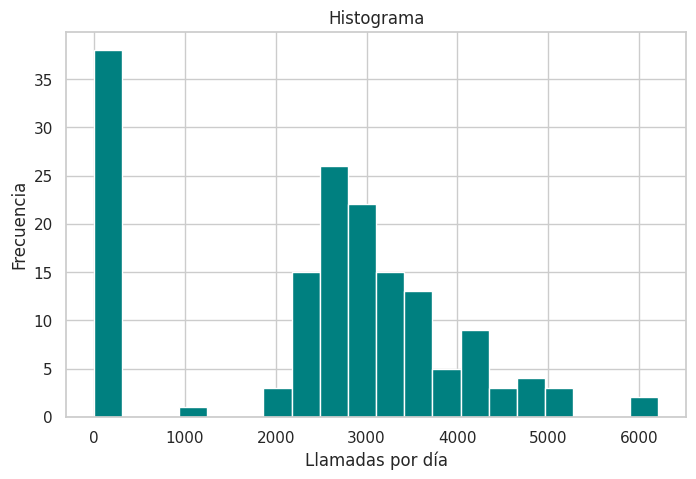

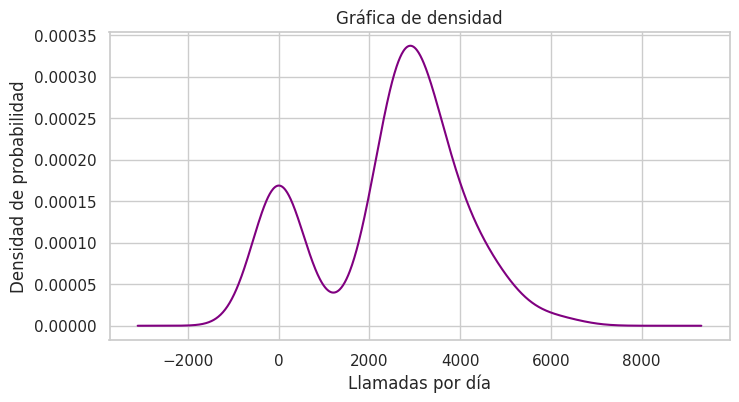

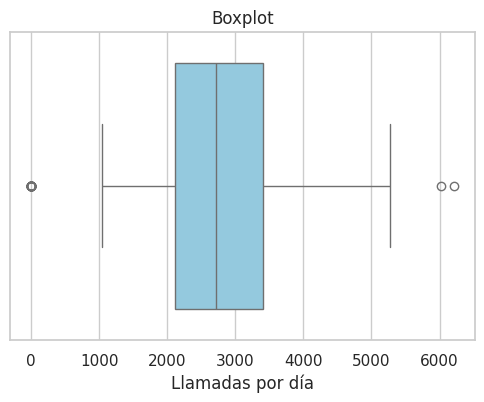

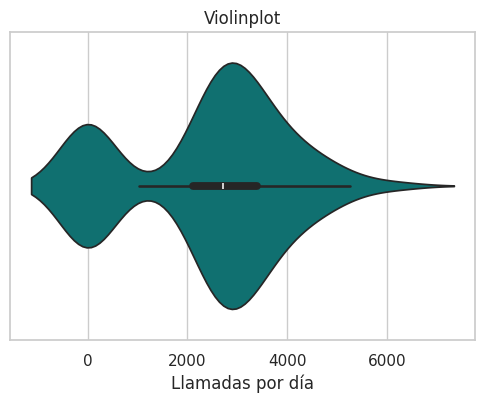

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

print( "============================================\n")
# Tabla de frecuencias
contingencia_absoluta = pd.crosstab(
    df_copia['alcaldia'],
    df_copia['categoria'],
    margins=True,
    margins_name="Total"
)
print(contingencia_absoluta.head())
print( "============================================\n")
# Porcentaje por Alcaldía (multiplicamos por 100 para verlo como %)
contingencia_porcentual = pd.crosstab(
    df_copia['alcaldia'],
    df_copia['categoria'],
    normalize='index'
) * 100
print(contingencia_porcentual.round(2).head())
print( "============================================\n")
#Histograma de frecuencia de llamadas
plt.figure(figsize=(8, 4))
top_dias_frecuencia = llamadas_por_dia.value_counts().head(10)
sns.barplot(x=top_dias_frecuencia.index, y=top_dias_frecuencia.values, color="skyblue")
plt.title("Conteos más comunes de llamadas por día")
plt.xlabel("Frecuencia ")
plt.ylabel("Número de días")
plt.show()

# Histograma de llamadas diarias
plt.figure(figsize=(8,5))
llamadas_por_dia.hist(bins=20, color='teal')
plt.title("Histograma")
plt.xlabel("Llamadas por día")
plt.ylabel("Frecuencia")
plt.show()

# Gráfica de densidad
plt.figure(figsize=(8, 4))
llamadas_por_dia.plot(kind='density', color='purple')
plt.title("Gráfica de densidad")
plt.xlabel("Llamadas por día")
plt.ylabel("Densidad de probabilidad")
plt.show()

#Boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(x=llamadas_por_dia, color='skyblue')
plt.title("Boxplot")
plt.xlabel("Llamadas por día")
plt.show()

#Violinplot
plt.figure(figsize=(6, 4))
sns.violinplot(x=llamadas_por_dia, color='teal')
plt.title("Violinplot")
plt.xlabel("Llamadas por día")
plt.show()

En las gráficas es posible observar de manera más clara el análisis de las medidas de tendencia central que se realizó antes, confirmando que 2720 es el valor de número de llamadas que representa un día normal en CDMX y que los valores normales están entre 2115 y 3403 llamadas diarias y que los valores atípicos son de 1 llamada, y hasta 6 mil o más llamadas al día.

# 3. Exploración de variables categóricas y análisis multivariable

Tabla de contingencia 
categoria              Abandono  Accidente  Administrativas  Agresion  \
alcaldia                                                                
ALVARO OBREGON              327          2             2809      3931   
AZCAPOTZALCO                206          0             1897      2525   
BENITO JUAREZ               250          0             1446      3207   
COYOACAN                    313          0             2992      4241   
CUAJIMALPA                    0          0                0         1   
CUAJIMALPA DE MORELOS        53          0              423       762   
CUAUHTEMOC                  282          0             3070      6682   
GUSTAVO A. MADERO           711          1             5030      6778   
IZTACALCO                   230          0             2202      2966   
IZTAPALAPA                  831          0             6182     10447   

categoria              Amenaza  Cadaver  Contra la salud  Danos  \
alcaldia                         

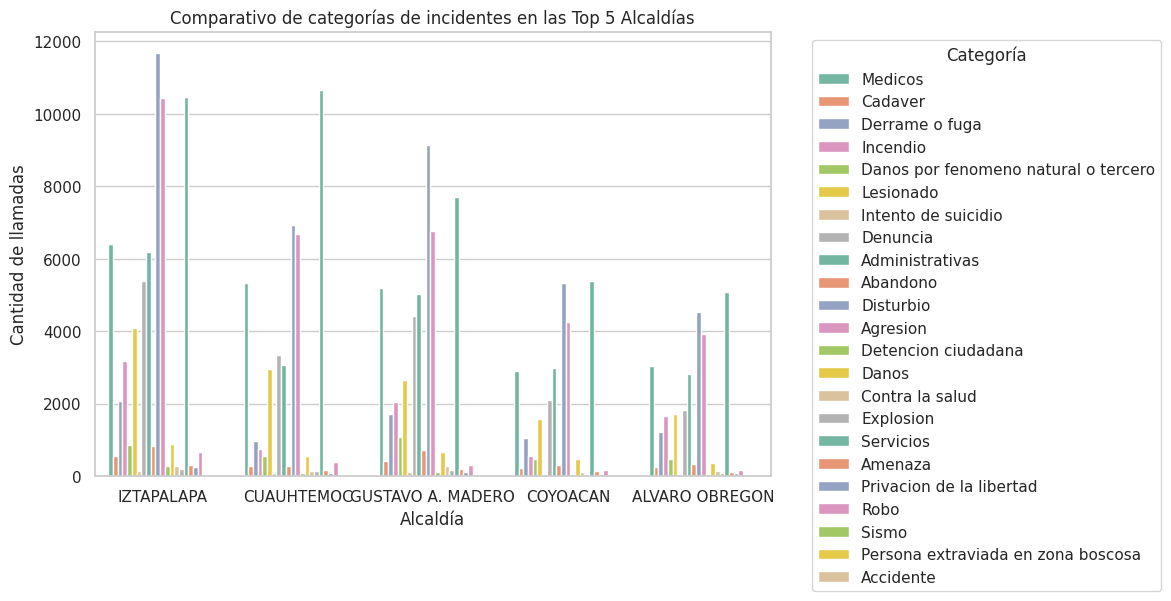

In [ ]:
tabla_contingencia = pd.crosstab(df_copia['alcaldia'], df_copia['categoria'], margins=True)
print("Tabla de contingencia ")
print(tabla_contingencia.head(10))

# Gráfica
top_5_alcaldias = df_copia['alcaldia'].value_counts().head(5).index
df_top5 = df_copia[df_copia['alcaldia'].isin(top_5_alcaldias)]

plt.figure(figsize=(12, 6))
sns.countplot(data=df_top5, x='alcaldia', hue='categoria', palette='Set2')
plt.title("Comparativo de categorías de incidentes en las Top 5 Alcaldías")
plt.xlabel("Alcaldía")
plt.ylabel("Cantidad de llamadas")
plt.legend(title="Categoría", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Se observa que las categorías más demandas son la de Servicios, Disturbio o alteración del orden y seguridad o agresión. De ls cuales, Iztapalapa y Cuauhtémoc registran la mayor parte de las llamadas. Las categorrías de sismo, derrame, fuga o persona extraviada son las categorías con menor demanda.

# 4. Correlaciones y regresión lineal simple

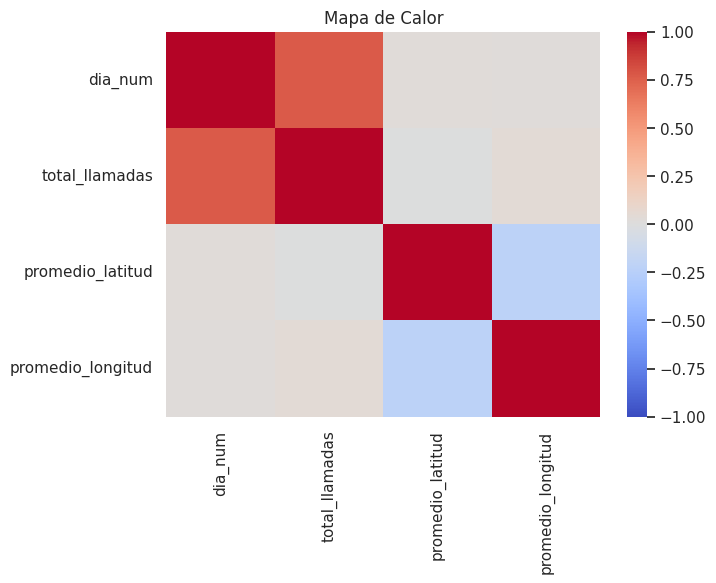

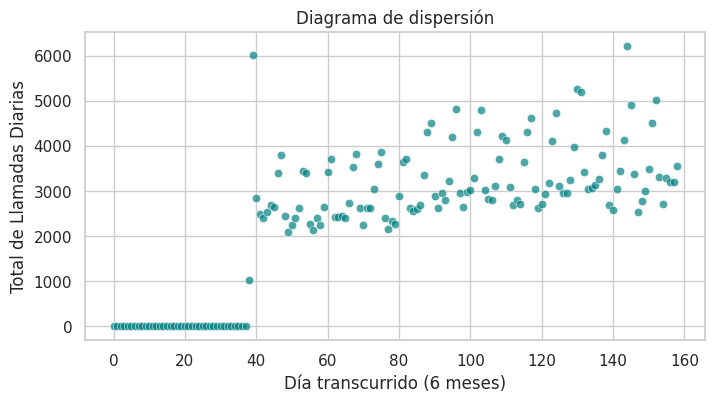

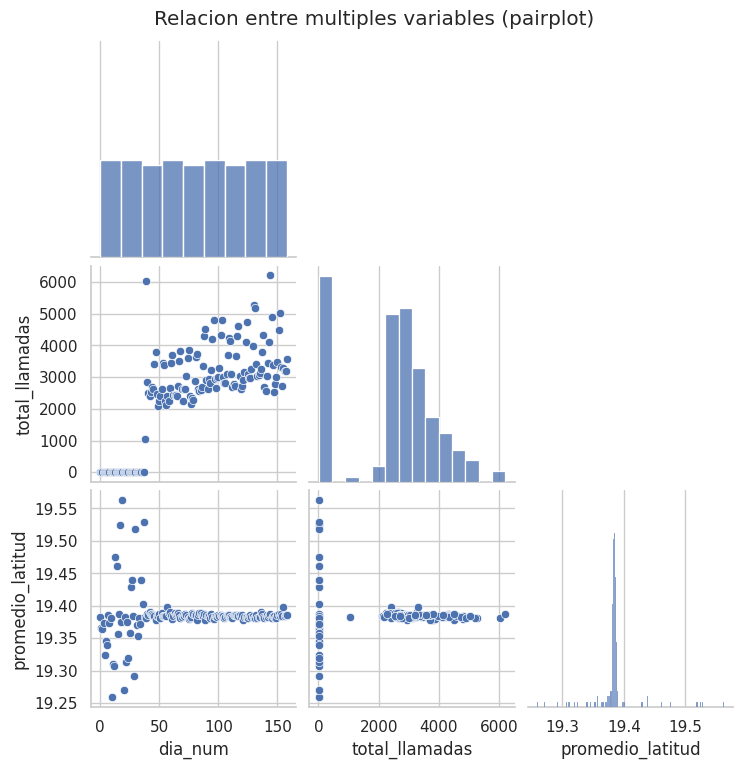

Resultados
Coeficiente de Correlación de Pearson: 0.7673
Pendiente (m): 26.07
Intercepto (b): 393.64
Coeficiente de Determinación (R²): 0.5888


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

df_diario = df_copia.groupby(df_copia['fecha_creacion'].dt.date).agg(
    total_llamadas=('folio', 'count'),
    promedio_latitud=('latitud', 'mean'),
    promedio_longitud=('longitud', 'mean')
).reset_index()

df_diario['dia_num'] = np.arange(len(df_diario))

#Matriz de correlación
matriz_corr = df_diario[['dia_num', 'total_llamadas', 'promedio_latitud', 'promedio_longitud']].corr()

#Mapa de calor
plt.figure(figsize=(7, 5))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Mapa de Calor")
plt.show()

#Diagrama de dispersión
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_diario, x='dia_num', y='total_llamadas', color='teal', alpha=0.7)
plt.title("Diagrama de dispersión")
plt.xlabel("Día transcurrido (6 meses)")
plt.ylabel("Total de Llamadas Diarias")
plt.show()

#Relacion entre multiples variables
sns.pairplot(df_diario[['dia_num', 'total_llamadas', 'promedio_latitud']], corner=True)
plt.suptitle("Relacion entre multiples variables (pairplot)", y=1.02)
plt.show()

#Regresion lineal
X = df_diario[['dia_num']]          # Variable independiente (Predictor)
y = df_diario['total_llamadas']     # Variable dependiente (A predecir)

modelo = LinearRegression()
modelo.fit(X, y)

# Parámetros del modelo
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_
r2 = modelo.score(X, y)

print("Resultados")
print(f"Coeficiente de Correlación de Pearson: {df_diario['dia_num'].corr(y):.4f}")
print(f"Pendiente (m): {pendiente:.2f}")
print(f"Intercepto (b): {intercepto:.2f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")



Se confirman los valores atípicos de 1 llamada por día y que el incremento en el volumen de emergencias ocurre en toda la ciudad de manera lineal, además de que la demanda crece aproximadamente 26 llamadas cada día.

# 5. Distribuciones muestrales y técnicas de evaluación de modelos


In [ ]:
import numpy as np
from scipy import stats
from sklearn.utils import resample

# A. Bootstrap de la Media de Llamadas
medias_boot = []
for i in range(1000):
    muestra = resample(llamadas_por_dia, replace=True)
    medias_boot.append(muestra.mean())

print(f"Media : {np.mean(medias_boot):.2f}")
print(f"Desviación de las medias (SE Bootstrap): {np.std(medias_boot):.2f}")

media_real = llamadas_por_dia.mean()
error_estandar = stats.sem(llamadas_por_dia)

intervalo = stats.t.interval(
    confidence=0.95,
    df=len(llamadas_por_dia)-1,
    loc=media_real,
    scale=error_estandar
)

print(f"\nMedia real: {media_real:.2f}")
print(f"Error estándar: {error_estandar:.2f}")
print(f"Intervalo de confianza (95%): {intervalo[0]:.2f} a {intervalo[1]:.2f}")

Media Bootstrap: 2459.77
Desviación de las medias (SE Bootstrap): 122.81

Media Real: 2453.21
Error estándar: 124.07
Intervalo de Confianza (95%): 2208.17 a 2698.25


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Definimos la variable a predecir: 1 = Día de Alta Demanda, 0 = Día Normal
# Usamos el modelo de regresión que entrenamos antes para predecir
df_diario['AltaDemandaReal'] = (df_diario['total_llamadas'] > df_diario['total_llamadas'].median()).astype(int)

# Predicción simple: si el modelo estima más de la mediana, predice 1
predicciones_num = modelo.predict(df_diario[['dia_num']])
df_diario['PrediccionModelo'] = (predicciones_num > df_diario['total_llamadas'].median()).astype(int)

# Cálculo de métricas sencillas
precision = precision_score(df_diario['AltaDemandaReal'], df_diario['PrediccionModelo'])
recall = recall_score(df_diario['AltaDemandaReal'], df_diario['PrediccionModelo'])
f1 = f1_score(df_diario['AltaDemandaReal'], df_diario['PrediccionModelo'])

print(f"Precisión: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

# 6. Visualización de datos avanzada


# 7. Pruebas A/B y procesamiento de lenguaje natural


# 8. Introducción a machine learning: clasificación no supervisada y supervisada
